# 0 · Explore and train a baseline

**The project.** Map land cover from Sentinel-2 images. Each image has a label picture saying what is on the ground at every pixel. We open the data, check it, and train a small baseline with Lightning.

```text
data/dynamic_world/
├── train/  images/<id>.tif   labels/<id>.tif
├── val/    ...
└── test/   ...
```

300 tiles of [Dynamic World](https://doi.org/10.1594/PANGAEA.933475) labels, published as [fatmur/dynamicworld-300](https://huggingface.co/datasets/fatmur/dynamicworld-300). Notebook 1 improves the model, 2 rebuilds the inputs from STAC, 3 trains and publishes maps from that catalog.

Download the dataset (about 400 MB; running again only checks for changes).

In [1]:
from pathlib import Path

import lightning as L
from huggingface_hub import snapshot_download

# One seed for the whole notebook, so the model's first weights and the shuffled
# batches repeat from run to run.
L.seed_everything(0)

root = Path(
    snapshot_download(
        "fatmur/dynamicworld-300", repo_type="dataset", local_dir="data/dynamic_world"
    )
)

Seed set to 0


Fetching 603 files:   0%|          | 0/603 [00:00<?, ?it/s]

`gs.open_raster` returns a plain `xarray.Dataset`, one variable per band. The files carry the RGB band choice and the label's class names and colours, so `.gs.plot()` needs no settings.

<xarray.Dataset> Size: 2MB
Dimensions:      (x: 510, y: 510)
Coordinates:
  * x            (x) float64 4kB 3.703e+05 3.704e+05 ... 3.754e+05 3.754e+05
  * y            (y) float64 4kB 2.229e+06 2.229e+06 ... 2.224e+06 2.224e+06
    spatial_ref  int64 8B 0
    time         datetime64[ms] 8B 2019-01-30T17:15:41.024000
Data variables:
    B02          (y, x) uint16 520kB dask.array<chunksize=(510, 510), meta=np.ndarray>
    B03          (y, x) uint16 520kB dask.array<chunksize=(510, 510), meta=np.ndarray>
    B04          (y, x) uint16 520kB dask.array<chunksize=(510, 510), meta=np.ndarray>
    B08          (y, x) uint16 520kB dask.array<chunksize=(510, 510), meta=np.ndarray>
Attributes:
    TIFFTAG_IMAGEDESCRIPTION:  The [Sentinel-2](https://sentinel.esa.int/web/...
    id:                        sentinel-2-l2a
    institution:               ESA
    keywords:                  Sentinel, Copernicus, ESA, Satellite, Global, ...
    license:                   proprietary
    stac_groupby:              solar_day
    stac_items:                [{"id":"S2A_MSIL2A_20190130T171541_R112_T14QLH...
    summary:                   The [Sentinel-2](https://sentinel.esa.int/web/...
    title:                     Sentinel-2 Level-2A
    AREA_OR_POINT:             Area

:Layout
   .RGB.I     :RGB   [x,y]   (R,G,B)
   .Overlay.I :Overlay
      .RGB.I                     :RGB   [x,y]   (R,G,B)
      .Points.Water              :Points   [x,y]
      .Points.Trees              :Points   [x,y]
      .Points.Grass              :Points   [x,y]
      .Points.Flooded_vegetation :Points   [x,y]
      .Points.Crops              :Points   [x,y]
      .Points.Scrub              :Points   [x,y]
      .Points.Built_area         :Points   [x,y]
      .Points.Bare_ground        :Points   [x,y]
      .Points.Snow_ice           :Points   [x,y]
      .Points.Cloud              :Points   [x,y]
      .Points.Unlabelled         :Points   [x,y]
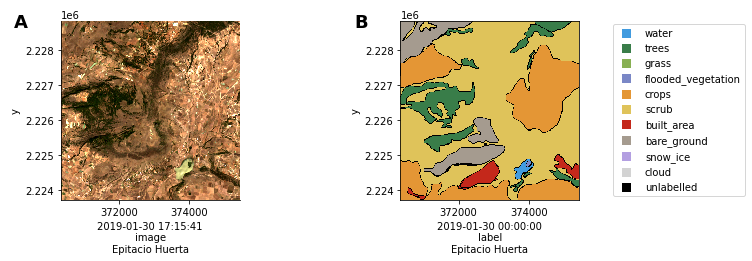

In [2]:
from IPython.display import display

import geosave as gs

images = sorted((root / "train/images").glob("*.tif"))
labels = sorted((root / "train/labels").glob("*.tif"))

image = gs.open_raster(images[0])
label = gs.open_raster(labels[0])

display(image)
gs.tree({"image": image, "label": label}).gs.plot(cols=2)

## Explore

In [3]:
train_images = [gs.open_raster(path).gs.mask_and_scale() for path in images]
train_labels = [gs.open_raster(path)["label"] for path in labels]

gs.statistics(train_images[:5])

,minimum,maximum,mean,stddev,valid_percent
B02,0.0001,0.8036,0.062366,0.041126,100.0
B03,0.0001,0.8144,0.085485,0.045689,100.0
B04,0.0001,0.8376,0.100540,0.062526,100.0
B08,0.0087,1.0336,0.214875,0.060943,100.0


Reflectance is on a `0`–`~1.8` scale with almost no missing pixels. Share of each class across the training labels:

In [4]:
percent = gs.class_percent(train_labels[:5])
percent.plot.barh(title="Training labels: % of pixels", figsize=(6, 3))
percent.round(1)

water                  0.3
trees                 23.7
grass                  0.3
flooded_vegetation     0.0
crops                 26.6
scrub                 32.2
built_area            14.9
bare_ground            2.0
snow_ice               0.0
cloud                  0.0
Name: percent, dtype: float64

Trees, scrub and water dominate; cloud is rare. Report mIoU next to accuracy, since accuracy alone rewards the common classes.

`.gs.to_tensor()` turns the named bands into a `(bands, height, width)` tensor. Reflectance is stored as integers 10,000 times larger, so `mask_and_scale` restores it. `DynamicWorld` receives image and label TIFF paths, opens each requested pair in `__getitem__`, and returns an `(image, label)` pair. Missing image pixels become 0; missing labels become 255, which the loss ignores. We reuse this Dataset in notebooks 1 and 3.

In [5]:
import torch
from torch.utils.data import DataLoader, Dataset


class DynamicWorld(Dataset):
    def __init__(self, images, labels=None):
        self.images = images
        self.labels = labels if labels else None

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = gs.open_raster(self.images[index])
        image = image.gs.mask_and_scale().gs.to_tensor(dtype="float32")
        image = image.nan_to_num()  # (4, H, W)
        if self.labels is None:
            return image

        label = gs.open_raster(self.labels[index])["label"]
        label = label.gs.mask_and_scale().gs.to_tensor(dtype="float32")
        label = label.nan_to_num(255).long()  # (H, W)
        return image, label


val_images = sorted((root / "val/images").glob("*.tif"))
val_labels = sorted((root / "val/labels").glob("*.tif"))

train = DynamicWorld(images, labels)
val = DynamicWorld(val_images, val_labels)
train_loader = DataLoader(train, batch_size=8, shuffle=True)
val_loader = DataLoader(val, batch_size=8)

image, label = train[0]
len(train), len(val), image.shape, label.shape

(200, 50, torch.Size([4, 510, 510]), torch.Size([510, 510]))

An encoder turns pixels into features, a decoder brings them back to full size, and a head scores each of the 10 classes.

In [6]:
from torch import nn


class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(4, 16, 3, stride=2, padding=1), nn.ReLU())

    def forward(self, image):
        return self.net(image)  # (B, 4, H, W) -> (B, 16, H/2, W/2)


class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Upsample(scale_factor=2), nn.Conv2d(16, 16, 3, padding=1), nn.ReLU()
        )

    def forward(self, features):
        return self.net(features)  # (B, 16, H/2, W/2) -> (B, 16, H, W)


class Head(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Conv2d(16, 10, 1)

    def forward(self, features):
        return self.net(features)  # (B, 16, H, W) -> (B, 10, H, W)


model = nn.Sequential(Encoder(), Decoder(), Head())
model

Sequential(
  (0): Encoder(
    (net): Sequential(
      (0): Conv2d(4, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): ReLU()
    )
  )
  (1): Decoder(
    (net): Sequential(
      (0): Upsample(scale_factor=2.0, mode='nearest')
      (1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
    )
  )
  (2): Head(
    (net): Conv2d(16, 10, kernel_size=(1, 1), stride=(1, 1))
  )
)

Plain Lightning. Class 255 is ignored by the loss and metrics; mIoU is the usual segmentation score.

In [7]:
import lightning as L
from torchmetrics import MetricCollection
from torchmetrics.classification import MulticlassAccuracy, MulticlassJaccardIndex


class Segmenter(L.LightningModule):
    def __init__(self, model):
        super().__init__()
        self.model = model
        self.val_metrics = MetricCollection(
            {
                "miou": MulticlassJaccardIndex(num_classes=10, ignore_index=255),
                "accuracy": MulticlassAccuracy(
                    num_classes=10, ignore_index=255, average="micro"
                ),
            },
            prefix="val_",
        )
        self.criterion = nn.CrossEntropyLoss(ignore_index=255)

    def forward(self, image):
        return self.model(image)

    def training_step(self, batch, batch_index):
        image, label = batch  # (B, C, H, W), (B, H, W)
        logits = self(image)  # (B, classes, H, W)
        loss = self.criterion(logits, label)
        self.log("train_loss", loss, on_step=True, on_epoch=True)
        return loss

    def validation_step(self, batch, batch_index):
        image, label = batch  # (B, C, H, W), (B, H, W)
        logits = self(image)  # (B, classes, H, W)
        loss = self.criterion(logits, label)
        self.log("val_loss", loss)
        self.val_metrics(logits, label)
        self.log_dict(self.val_metrics)

    def configure_optimizers(self):
        return torch.optim.AdamW(self.parameters(), lr=1e-2)


module = Segmenter(model)

Six short epochs on a CPU take a couple of minutes. Remove the batch limits and raise `max_epochs` to train longer. Running the cell again resumes from `last.ckpt`; delete `lightning_logs/00_basics` to start afresh.

In [8]:
import warnings

from lightning.pytorch.callbacks import ModelCheckpoint
from lightning.pytorch.loggers import TensorBoardLogger

# The tiles are small and few; Lightning's hint to add loader workers is noise here.
warnings.filterwarnings("ignore", ".*does not have many workers.*")

# Each notebook logs to a folder of its own; version 0 is its one run.
logger = TensorBoardLogger("lightning_logs", name="00_basics", version=0)
# The last epoch is kept, so running this cell again resumes the finished run.
checkpoint = ModelCheckpoint(save_last=True)

trainer = L.Trainer(
    max_epochs=6,
    limit_train_batches=6,
    limit_val_batches=2,
    log_every_n_steps=1,
    logger=logger,
    callbacks=[checkpoint],
)
trainer.fit(module, train_loader, val_loader, ckpt_path="last")

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/uwu/Projects/geosave/.venv/lib/python3.14/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory lightning_logs/00_basics/version_0/checkpoints exists and is not empty.
Restoring states from the checkpoint path at /home/uwu/Projects/geosave/examples/lightning_logs/00_basics/version_0/checkpoints/last.ckpt


┏━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name        ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model       │ Sequential       │  3.1 K │ train │     0 │
│ 1 │ val_metrics │ MetricCollection │      0 │ train │     0 │
│ 2 │ criterion   │ CrossEntropyLoss │      0 │ train │     0 │
└───┴─────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 3.1 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 3.1 K                                                                                                
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 16                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Restored all states from the checkpoint at /home/uwu/Projects/geosave/examples/lightning_logs/00_basics/version_0/checkpoints/last.ckpt


Output()

/home/uwu/Projects/geosave/.venv/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: 
`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

/home/uwu/Projects/geosave/.venv/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: 
`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

`Trainer.fit` stopped: `max_epochs=6` reached.


Compare `train_loss_step` with `val_loss` for generalisation, and `val_miou` and `val_accuracy` per epoch.

In [9]:
%load_ext tensorboard
%tensorboard --logdir lightning_logs

Reusing TensorBoard on port 6006 (pid 57992), started 6:30:18 ago. (Use '!kill 57992' to kill it.)

Predict a validation tile and put the result on the label's grid with `gs.raster`, so both plot with the same legend.

:Layout
   .RGB.I      :RGB   [x,y]   (R,G,B)
   .Overlay.I  :Overlay
      .RGB.I                     :RGB   [x,y]   (R,G,B)
      .Points.Water              :Points   [x,y]
      .Points.Trees              :Points   [x,y]
      .Points.Grass              :Points   [x,y]
      .Points.Flooded_vegetation :Points   [x,y]
      .Points.Crops              :Points   [x,y]
      .Points.Scrub              :Points   [x,y]
      .Points.Built_area         :Points   [x,y]
      .Points.Bare_ground        :Points   [x,y]
      .Points.Snow_ice           :Points   [x,y]
      .Points.Cloud              :Points   [x,y]
      .Points.Unlabelled         :Points   [x,y]
   .Overlay.II :Overlay
      .RGB.I                     :RGB   [x,y]   (R,G,B)
      .Points.Water              :Points   [x,y]
      .Points.Trees              :Points   [x,y]
      .Points.Grass              :Points   [x,y]
      .Points.Flooded_vegetation :Points   [x,y]
      .Points.Crops              :Points   [x,y]
      .Points.Scrub              :Points   [x,y]
      .Points.Built_area         :Points   [x,y]
      .Points.Bare_ground        :Points   [x,y]
      .Points.Snow_ice           :Points   [x,y]
      .Points.Cloud              :Points   [x,y]
      .Points.Unlabelled         :Points   [x,y]
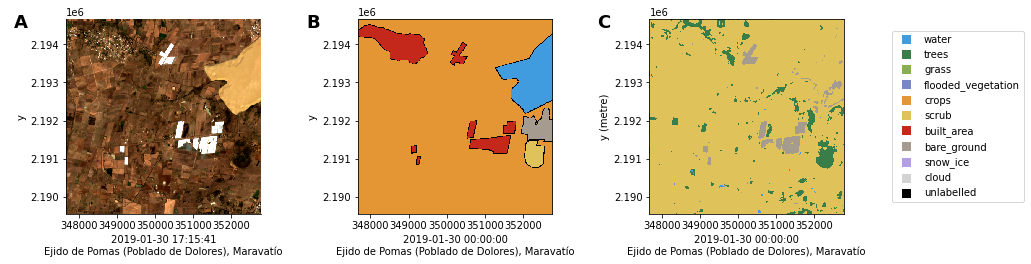

In [10]:
images, _ = next(iter(val_loader))  # (B, C, H, W)
module.eval()
with torch.no_grad():
    logits = module(images.to(module.device)).cpu()  # (B, classes, H, W)
    # Dim 0 is the batch, so classes are dim 1; [0] keeps the first tile.
    prediction = logits.argmax(dim=1)[0]  # (H, W)

image = gs.open_raster(val_images[0])
label = gs.open_raster(val_labels[0])["label"]
pred = prediction.numpy().astype("uint8")
predicted = gs.raster(
    variables={
        "label": (("y", "x"), pred)
    },  # y x is the dims assigned to the numpy array
    reference=label,
    nodata=255,
)

image.gs.plot() + label.gs.plot() + predicted.gs.plot()

## What happened

We opened satellite files as xarray Datasets, summarised them with `gs.statistics` and `gs.class_percent`, turned bands into tensors, trained with Lightning, and put a prediction back on the tile's grid. Six epochs only show the loop works; expect poor predictions.

| Next | Question |
| --- | --- |
| 1 · Model | How do I grow this model, swap its parts and compare runs? |
| 2 · Build a dataset | How do I build a dataset like this for my own labels, places and dates? |
| 3 · Train and predict | How do I train on my own dataset and map an unlabelled place? |

## Your turn

The exercises go from easy to advanced. Each has an empty cell below it, with hints and a solution folded under it.

### 1 · Another tile (easy)

Open the fifth validation picture and its labels and plot them side by side, as at the top of this notebook. Which classes does the legend show?

<details><summary>Solution</summary>

```python
image = val.images[4]
label = val.labels[4]
gs.tree({"image": image, "label": label}).gs.plot(cols=2)
```
</details>

In [11]:
# Your code here

### 2 · Train longer (easy)

Six short epochs only show the loop working. Make a new `Segmenter`, remove `limit_train_batches` and `limit_val_batches`, raise `max_epochs` to 20 and log as `00_basics_long`. In TensorBoard, does `val_loss` keep falling, or start to rise while `train_loss` falls?

<details><summary>Hint</summary>

Copy the training cell. Use a new `TensorBoardLogger("lightning_logs", name="00_basics_long", version=0)`, so the run gets its own curves, and a fresh `Segmenter(nn.Sequential(Encoder(), Decoder(), Head()))`, so it does not continue from the trained weights.
</details>

In [12]:
# Your code here

### 3 · Which class is rarest? (easy)

Which class does the model see least, and how much of the training labels is it?

<details><summary>Solution</summary>

```python
percent.idxmin(), percent.min()
```
</details>

In [13]:
# Your code here

### 4 · Weigh the rare classes (advanced)

Give `nn.CrossEntropyLoss` a `weight` per class, larger for rare ones. Train as `00_weighted` and compare `val_miou` with this run in TensorBoard.

<details><summary>Hint</summary>

Inverse share: `weight = torch.tensor(percent.max() / percent.values, dtype=torch.float32)`. Give `Segmenter` a `weight` argument and pass it to `nn.CrossEntropyLoss(weight=weight, ignore_index=255)`.
</details>

In [14]:
# Your code here